# Sensibilidades e permanência prolongada

As seis sensibilidades refazem o X3, os trimestres de 2023 a 2025 com as sete estratégias, mudando uma coisa de cada
vez; os resultados estão em `reports/exploratorios/morte/s1/` a `s6/`, com um `resumo.json` em cada pasta. A permanência
prolongada, de 8 dias ou mais, é o desfecho secundário, com X3 e X4 em `reports/exploratorios/perm_prolongada/nenhuma/`
e as figuras em `reports/figures/perm_prolongada/`.

In [1]:
import json

import pandas as pd
from IPython.display import Image

from triagem_baixo_risco import config
from triagem_baixo_risco.avaliacao import h3
from triagem_baixo_risco.plots import LABELS

EXPLORATORIOS = config.REPORTS_DIR / "exploratorios"
pd.set_option("display.max_colwidth", None)


def pct(x, casas=2):
    return f"{100 * x:.{casas}f}%".replace(".", ",")


def num(x, casas=0):
    # 1234567.891 com casas=2 vira "1.234.567,89"
    return f"{x:,.{casas}f}".replace(",", " ").replace(".", ",").replace(" ", ".")


def pv(p):
    return "< 0,0001" if p < 0.0001 else num(p, 4)


def ler(desfecho, sensibilidade, nome):
    return json.loads((EXPLORATORIOS / desfecho / sensibilidade / f"{nome}.json").read_text())


def motivo_g1(v):
    return ", ".join(v["periodos_violados"] + (["agregado"] if v["agregado"]["p_violacao"] < 0.05 else []))


def motivo_g2(v):
    return ", ".join(c for c, x in zip(("i", "ii", "iii"), v["criterios"]) if x)


def onde(h, motivo, experimento="x3"):
    grupos = {}
    for cenario, v in h["cenarios"].items():
        if v["refuta"] and cenario.startswith(experimento):
            grupos.setdefault(motivo(v), []).append(cenario.removeprefix(f"{experimento}_"))
    return "; ".join(f"{', '.join(e)} ({m})" for m, e in grupos.items()) or "-"


def decisao_h3(r):
    return f"{'sim' if r['refutada'] else 'não'} (Wilcoxon {pv(r['p_wilcoxon'])}; McNemar {pv(r['p_mcnemar'])})"

## Sensibilidades no X3

Em cada célula estão as estratégias que refutam a hipótese e, entre parênteses, os trimestres violados, com "agregado"
quando a FDL somada também é significativa, ou os critérios de H2. A primeira linha é a análise principal só com o X3, e
o H3 dela foi recalculado com esses 12 trimestres, para ficar comparável.

In [2]:
NOMES = {
    "nenhuma": "análise principal",
    "s1": "S1, isotônica",
    "s2": "S2, sem o CID de 3 caracteres",
    "s3": "S3, sem as censuradas",
    "s4": "S4, coorte pela competência",
    "s5": "S5, óbito por episódio",
    "s6": "S6, sem hospital e município de atendimento",
}
x3_principal = ler("morte", "nenhuma", "resultados_x3")
tabela = {}
for s, nome in NOMES.items():
    hip = ler("morte", s, "resumo")["hipoteses_exploratorias"]
    tabela[nome] = {
        "H1": onde(hip["h1"], motivo_g1),
        "H1b": onde(hip["h1b"], motivo_g1),
        "H2": onde(hip["h2"], motivo_g2),
        "H3": decisao_h3(h3(list(zip(x3_principal["a"], x3_principal["c"]))) if s == "nenhuma" else hip["h3"]),
    }
pd.DataFrame(tabela).T.rename_axis("sensibilidade")

,H1,H1b,H2,H3
sensibilidade,,,,
análise principal,"a, e, g (2024T1)",-,b (iii); g (ii),"não (Wilcoxon 0,0015; McNemar 1,0000)"
"S1, isotônica",-,-,d (iii); g (ii),"não (Wilcoxon 0,0015; McNemar 1,0000)"
"S2, sem o CID de 3 caracteres",-,-,g (ii),"não (Wilcoxon 0,0015; McNemar 1,0000)"
"S3, sem as censuradas","a, e, g (2023T4, 2024T1, agregado); b, c, d (2023T4); f (2023T4, 2024T1)","a, b, c, d, e, f, g (2023T4)",c (iii); g (ii),"não (Wilcoxon 0,0068; McNemar 1,0000)"
"S4, coorte pela competência","a, g (2024T1, 2024T2); e (2024T1)",-,"b, c, d, f (iii); g (ii, iii)","não (Wilcoxon 0,0034; McNemar 1,0000)"
"S5, óbito por episódio","a, b, c, e, f, g (2024T1)",-,g (ii),"não (Wilcoxon 0,0024; McNemar 1,0000)"
"S6, sem hospital e município de atendimento","a, e, f, g (2024T1)",-,"b, c (iii); g (ii)","não (Wilcoxon 0,0010; McNemar 1,0000)"


H3 não é refutada em nenhuma sensibilidade, e H2 é refutada em todas, sempre pela (g) no critério (ii). As diferenças
estão em H1.

Com a isotônica (S1) ou sem o CID de 3 caracteres (S2), nenhuma estratégia viola G1. Sem as AIH censuradas (S3), 2023T4
passa a violar G1 nas sete estratégias, o agregado de (a), (e) e (g) também, e H1b cai junto: tirar os óbitos em surto
não desfaz a violação desse trimestre. Nas outras três, o problema continua em 2024T1. Na S4, com a coorte pela
competência, 2024T2 se junta a ele em (a) e (g). O óbito por episódio (S5) deixa 2024T1 violado em seis das sete
estratégias, e sem hospital e município de atendimento (S6) são quatro. Nessas três, H1b não é refutada.

In [3]:
ligacao = ler("morte", "s5", "resumo")["info"]["taxas_ligacao"]
print("AIH de permanência ligadas à seguinte:", pct(ligacao["permanencia_ligadas"], 1))
print("AIH de transferência ligadas à seguinte:", pct(ligacao["transferencias_ligadas"], 1))

AIH de permanência ligadas à seguinte: 91,7%
AIH de transferência ligadas à seguinte: 49,3%


Na S5, a ligação de episódios juntou 91,7% das AIH de permanência à AIH seguinte e 49,3% das de transferência. Uma
transferência para um hospital de fora da região não tem AIH seguinte na base, e isso deve explicar parte das que
ficaram sem par.

## Permanência prolongada

Aqui, liberar é tratar a internação como de baixo risco de ficar 8 dias ou mais. G1 limita a fração das permanências
prolongadas que a regra libera, e G2, a taxa de permanência prolongada entre as liberadas. H3 junta os trimestres de X3
e X4.

In [4]:
perm = ler("perm_prolongada", "nenhuma", "resumo")
hip = perm["hipoteses_exploratorias"]
print("refutadas:", ", ".join(h.upper() for h, r in hip.items() if r["refutada"]))
print("H3:", decisao_h3(hip["h3"]))
pd.DataFrame(
    {
        experimento: {
            "H1": onde(hip["h1"], motivo_g1, experimento),
            "H1b": onde(hip["h1b"], motivo_g1, experimento),
            "H2": onde(hip["h2"], motivo_g2, experimento),
        }
        for experimento in ("x3", "x4")
    }
).T

refutadas: H1, H1B, H2
H3: não (Wilcoxon 0,0123; McNemar 0,7500)


,H1,H1b,H2
x3,"a, e, g (2024T1, 2024T2, agregado); b (2024T2); c, f (2024T1, 2024T2)",-,"a, b, e (iii); g (ii, iii)"
x4,"b (2021T1, 2021T2, 2021T3, 2021T4); c (2021T1, 2021T2, 2021T3); f (2021T1, 2021T2, 2021T3, 2021T4, agregado)","b (2021T2, 2021T3, 2021T4); c (2020T4, 2021T2, 2021T3); f (2020T4, 2021T2, 2021T3, 2021T4, agregado)","b, c (ii); g (i, iii)"


Na permanência prolongada, G1 falha mais que no óbito. No X3, a estática viola G1 em 2024T1 e 2024T2, e o agregado dela
também é significativo. No X4, as estratégias que recalibram, (b), (c) e (f), violam G1 em três ou quatro trimestres de
2021, e nelas H1b também é refutada, porque as violações continuam sem os casos de diagnósticos em surto. A estática, a
(e) e a (g), que ficam com a calibração de 2019, atravessam a pandemia sem violar G1. H2 também cai, e H3 não, com
p = 0,0123 no Wilcoxon.

In [5]:
def rotulo(chave):
    estrategia, _, variante = chave.partition("(")
    variante = variante.rstrip(")").replace("gamma", "γ").replace("meia_vida", "meia-vida").replace(".", ",")
    return LABELS[estrategia] + (f", {variante}" if variante else "")


def por_estrategia(experimento):
    tabela = {}
    for chave, linhas in ler("perm_prolongada", "nenhuma", f"resultados_{experimento}").items():
        r = perm["resumo_estrategias"][f"{experimento}_{chave}"]
        k, n = sum(x["fdl_k"] for x in linhas), sum(x["fdl_n"] for x in linhas)
        tabela[rotulo(chave)] = {
            "|O/E - 1| médio": num(r["oe_desvio_medio"], 3),
            "trimestres com G1 violada": r["trimestres_g1_violada"],
            "trimestres com G2 violada": r["trimestres_g2_violada"],
            "liberadas, média": pct(r["fracao_liberada_media"], 1),
            "FDL agregada": pct(k / n),
        }
    return pd.DataFrame(tabela).T.rename_axis("estratégia")


por_estrategia("x3")

,|O/E - 1| médio,trimestres com G1 violada,trimestres com G2 violada,"liberadas, média",FDL agregada
estratégia,,,,,
(a) estática,"0,050",2,0,"49,1%","5,56%"
(b) anual,"0,032",1,0,"48,2%","5,10%"
(c) trimestral com atraso,"0,026",2,0,"48,2%","5,06%"
(d) retreino anual,"0,034",0,0,"49,2%","5,10%"
(e) conformal adaptativo,"0,050",2,0,"49,0%","5,54%"
(f) janela suave,"0,031",2,0,"48,5%","5,22%"
(g) correção de prevalência,"0,157",2,4,"49,1%","5,56%"
"(e) conformal adaptativo, γ=0,01","0,050",2,0,"49,1%","5,55%"
"(e) conformal adaptativo, γ=0,05","0,050",2,0,"48,9%","5,49%"


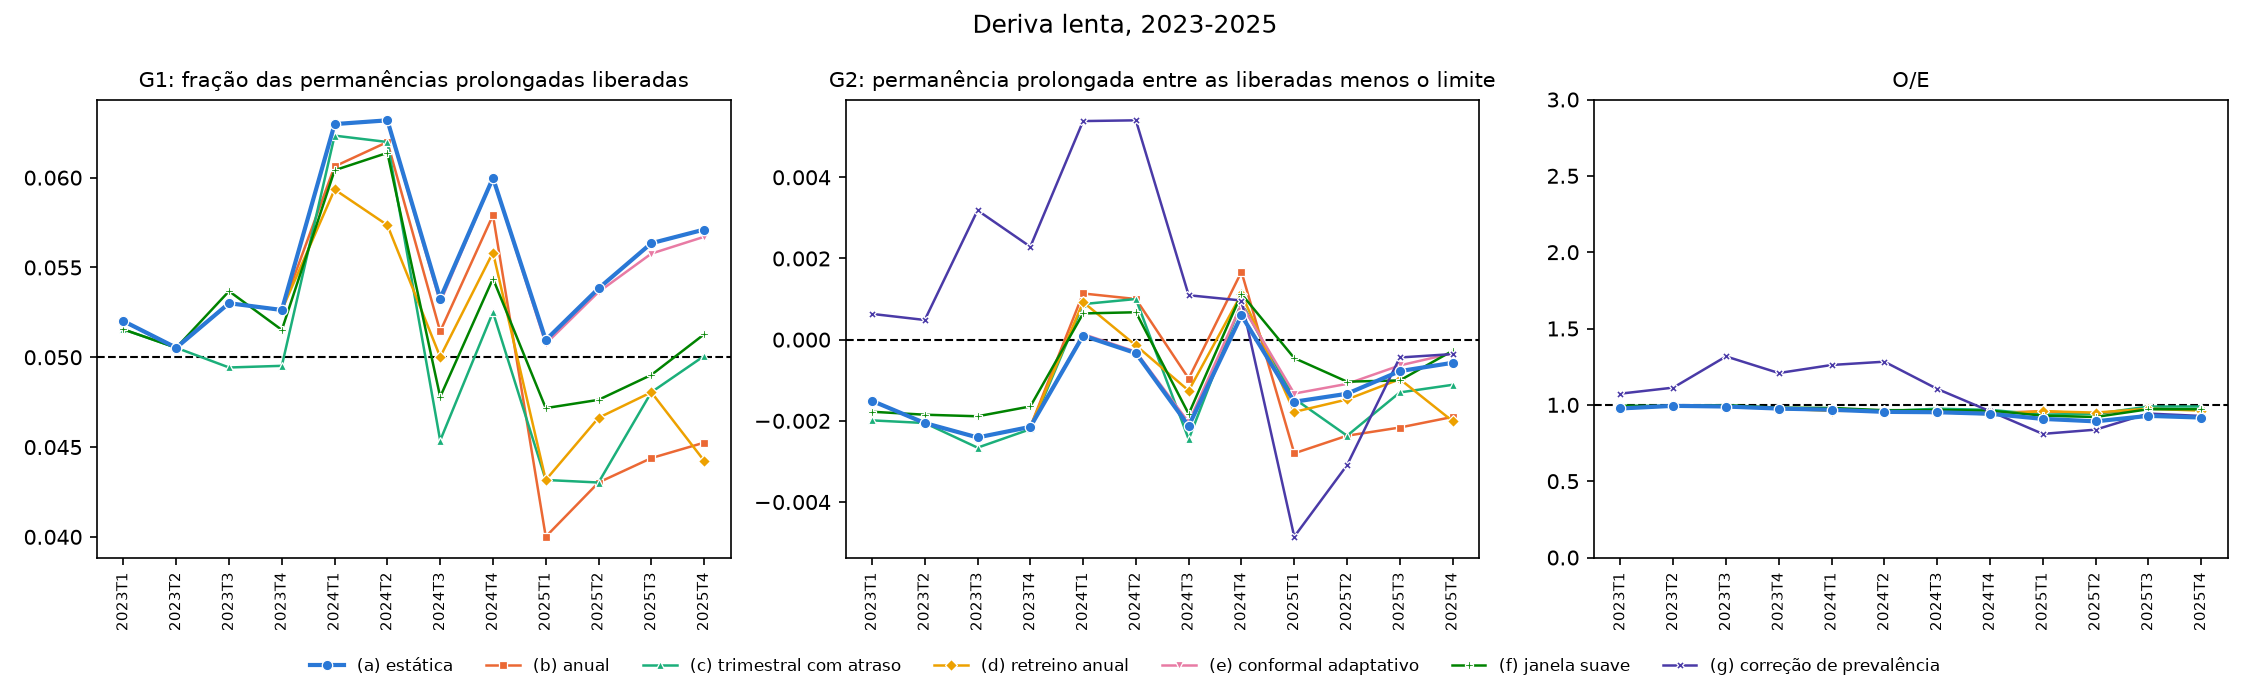

In [6]:
Image(filename=config.FIGURES_DIR / "perm_prolongada" / "garantias_x3.png")

Em 2023-2025, a regra liberou em média de 48,2% a 49,2% das internações, menos que no óbito, e a FDL agregada ficou
acima de 5% em todas as estratégias, de 5,06% na trimestral a 5,56% na estática. A (d), com o modelo retreinado, foi a
única sem trimestre de G1 violada.

In [7]:
por_estrategia("x4")

,|O/E - 1| médio,trimestres com G1 violada,trimestres com G2 violada,"liberadas, média",FDL agregada
estratégia,,,,,
(a) estática,"0,038",0,4,"43,4%","5,09%"
(b) anual,"0,053",4,4,"44,4%","5,63%"
(c) trimestral com atraso,"0,043",3,4,"44,3%","5,51%"
(e) conformal adaptativo,"0,038",0,4,"43,7%","5,21%"
(f) janela suave,"0,036",4,4,"44,5%","5,65%"
(g) correção de prevalência,"0,325",0,0,"43,4%","5,09%"
"(e) conformal adaptativo, γ=0,01","0,038",0,4,"43,4%","5,09%"
"(e) conformal adaptativo, γ=0,05","0,038",2,4,"44,0%","5,42%"
"(f) janela suave, meia-vida=2","0,036",5,4,"44,5%","5,60%"


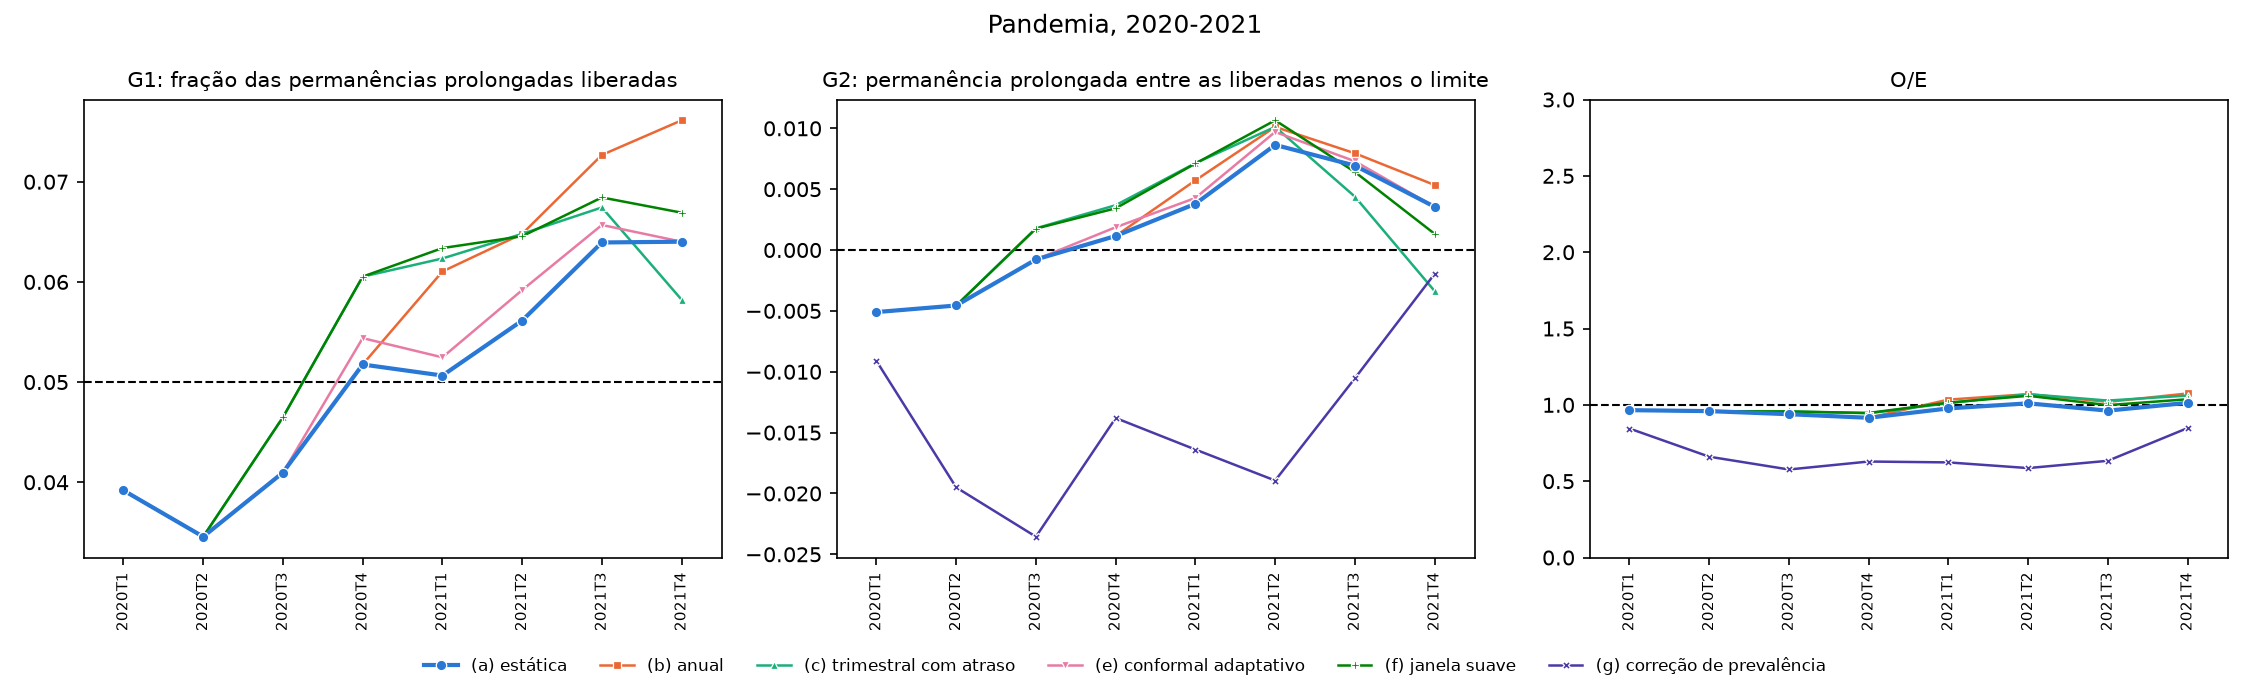

In [8]:
Image(filename=config.FIGURES_DIR / "perm_prolongada" / "garantias_x4.png")

Na pandemia, G2 falhou em quatro trimestres em todas as estratégias menos a (g), e a janela suave com meia-vida de 2
trimestres chegou a cinco trimestres com G1 violada. Recalibrar com dados da própria pandemia não protegeu G1 neste
desfecho.